In [71]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('ice_cream_sales_data.csv')
df['Counter'] = np.arange(1, len(df) + 1)
df

,Temperature,Humidity,Is_Weekend,Rainfall_Intensity,Sales_Revenue,Counter
0,34.540572,60.774939,0.0,0.919143,493.446603,1
1,22.176360,40.167044,1.0,2.515130,676.402807,2
2,15.301795,60.246362,1.0,9.031185,581.827992,3
3,24.557008,75.506242,0.0,0.961272,723.631829,4
4,35.806468,72.713934,0.0,1.367272,551.761034,5
...,...,...,...,...,...,...
20395,39.162778,59.883959,1.0,0.891168,668.557877,20396
20396,26.636939,74.982602,0.0,1.397169,462.274044,20397
20397,29.260794,50.375258,0.0,4.329173,NaN,20398
20398,31.848399,80.183649,1.0,1.066689,700.605913,20399


In [72]:

df['Temperature'] = round(df['Temperature'], 0)
df['Humidity'] = round(df['Humidity'], 0)
df['Rainfall_Intensity'] = round(df['Rainfall_Intensity'], 1)
df['Sales_Revenue'] = round(df['Sales_Revenue'], 2)

In [73]:
df.isnull().sum()

Temperature           404
Humidity              305
Is_Weekend             16
Rainfall_Intensity    208
Sales_Revenue         510
Counter                 0
dtype: int64

In [78]:
df['Is_Weekend'] = df['Is_Weekend'].dropna()
df['Is_Weekend'] = df['Is_Weekend'].astype(int)

IntCastingNaNError: Cannot convert non-finite values (NA or inf) to integer.Replace or remove non-finite values or cast to an integer typethat supports these values (e.g. 'Int64')

In [ ]:
avg_temperature = round(df['Temperature'].mean(), 2)
avg_humidity = round(df['Humidity'].mean(), 2)
avg_rainfall = round(df['Rainfall_Intensity'].mean(), 2)
print(f"Average Temperature: {avg_temperature}","\n",f"Average Humidity: {avg_humidity}","\n",f"Average Rainfall: {avg_rainfall}")

Average Temperature: 27.56 
 Average Humidity: 60.18 
 Average Rainfall: 2.02


In [ ]:
med_temperature = round(df['Temperature'].median(), 2)
med_humidity = round(df['Humidity'].median(), 2)
med_rainfall = round(df['Rainfall_Intensity'].median(), 2)
print(f"Median Temperature: {med_temperature}","\n",f"Median Humidity: {med_humidity}","\n",f"Median Rainfall: {med_rainfall}")

Median Temperature: 27.67 
 Median Humidity: 60.2 
 Median Rainfall: 1.4


In [ ]:
min_temperature = round(df['Temperature'].min(), 2)
max_temperature = round(df['Temperature'].max(), 2)
min_humidity = round(df['Humidity'].min(), 2)
max_humidity = round(df['Humidity'].max(), 2)
min_rainfall = round(df['Rainfall_Intensity'].min(), 2)
max_rainfall = round(df['Rainfall_Intensity'].max(), 2)
print(f"Minimum Temperature: {min_temperature}","\n",
      f"Maximum Temperature: {max_temperature}","\n",
      f"Minimum Humidity: {min_humidity}","\n",
      f"Maximum Humidity: {max_humidity}","\n",
      f"Minimum Rainfall: {min_rainfall}","\n",
      f"Maximum Rainfall: {max_rainfall}")

Minimum Temperature: -10.0 
 Maximum Temperature: 60.0 
 Minimum Humidity: 30.01 
 Maximum Humidity: 89.99 
 Minimum Rainfall: 0.0 
 Maximum Rainfall: 21.02


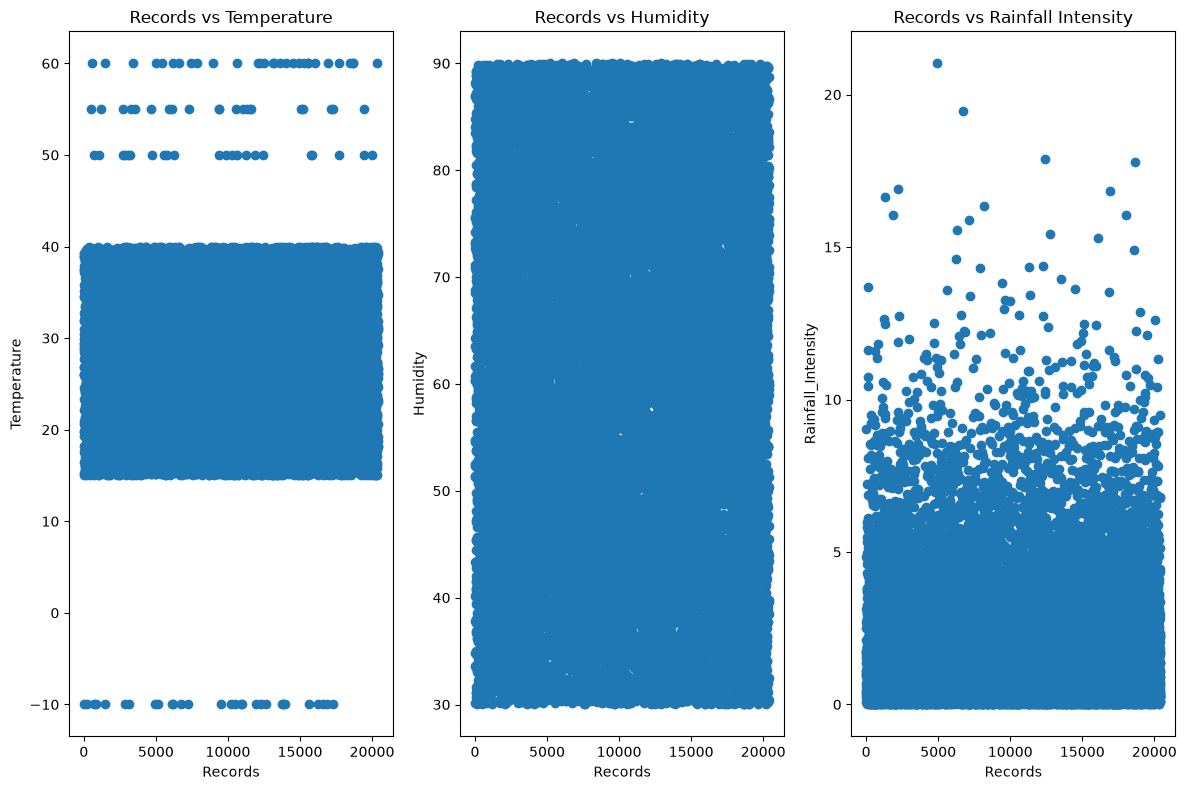

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12, 8))
plots = [
    ('Temperature', 'Records vs Temperature'),
    ('Humidity', 'Records vs Humidity'),
    ('Rainfall_Intensity', 'Records vs Rainfall Intensity')
]

for ax, (column, title) in zip(axes.flat, plots):
    ax.scatter(df['Counter'], df[column])
    ax.set_title(title)
    ax.set_xlabel('Records')
    ax.set_ylabel(column)

plt.tight_layout()
plt.show()

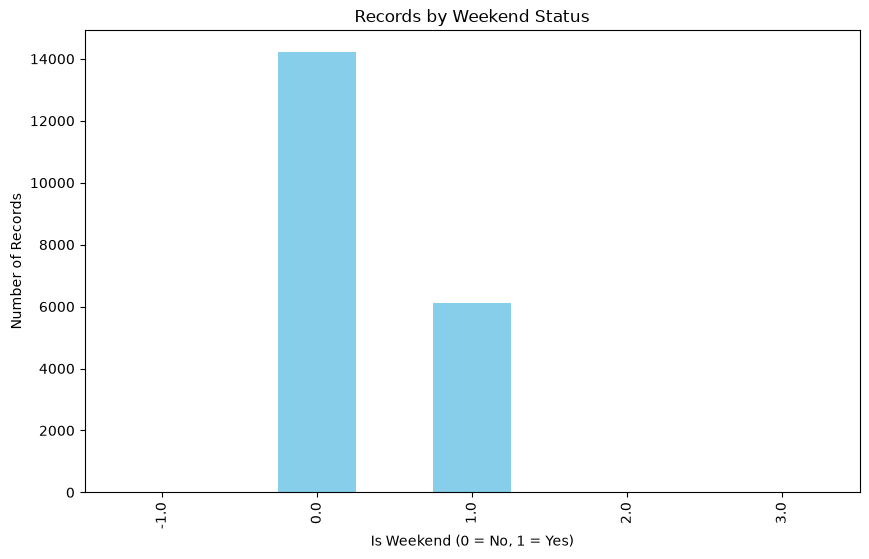

In [ ]:
df['Humidity'] = df['Humidity'].fillna(med_humidity)
df['Is_Weekend'].value_counts().sort_index().plot(
    kind='bar',
    figsize=(10, 6),
    color='skyblue'
)

plt.xlabel('Is Weekend (0 = No, 1 = Yes)')
plt.ylabel('Number of Records')
plt.title('Records by Weekend Status')
plt.show()

In [ ]:
df_inco = df[~df['Is_Weekend'].isin([0, 1])]

cnt = df_inco.shape[0]
cnt

61

In [ ]:
df = df.loc[df['Is_Weekend'].isin([0, 1])]
df

In [ ]:
df_extreme_temp = df[(df['Temperature'] < 0)]
counting = df_extreme_temp.shape[0]
print(f"Number of records with temperature less than 0: {counting}")

Number of records with temperature less than 0: 29


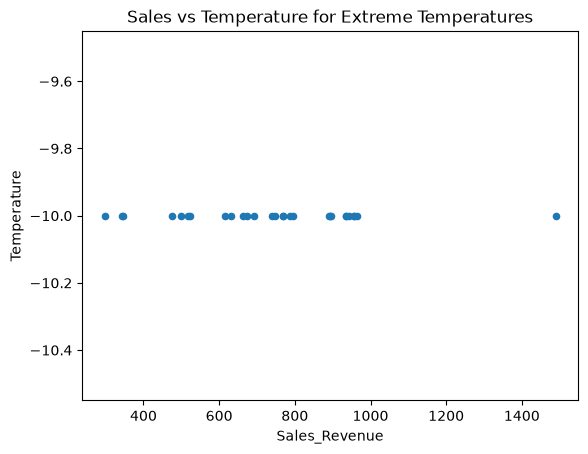

In [ ]:
plot = df_extreme_temp.plot(
    x='Sales_Revenue',
    y='Temperature',
    kind='scatter',
    title='Sales vs Temperature for Extreme Temperatures'
)

In [ ]:
df[['Temperature']]=df[['Temperature']].dropna()
df['Temperature'] = df['Temperature'].fillna(med_temperature)

In [ ]:
avg_sales = round(df['Sales_Revenue'].mean(), 2)
min_sales = round(df['Sales_Revenue'].min(), 2)
max_sales = round(df['Sales_Revenue'].max(), 2)
median_sales = round(df['Sales_Revenue'].median(), 2)
print(f"Average Sales Revenue: {avg_sales}","\n",
      f"Minimum Sales Revenue: {min_sales}","\n",
      f"Maximum Sales Revenue: {max_sales}","\n",
      f"Median Sales Revenue: {median_sales}")

Average Sales Revenue: 639.56 
 Minimum Sales Revenue: 0.0 
 Maximum Sales Revenue: 4761.84 
 Median Sales Revenue: 615.07


In [ ]:

df.isnull().sum()

Temperature             0
Humidity                0
Is_Weekend              0
Rainfall_Intensity      0
Sales_Revenue         503
Counter                 0
dtype: int64